In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Regla del Trapecio.

Vamos a leer los datos y a gráficar los datos para ver como se comportan 

In [2]:
# Vamos a leer los archivos usando un programa que ya teniamos de la tarea 3 

entrada = open("data/velocidades.txt", "r")    # esto es un buffer
datos = [[], []]
for linea in entrada:
    #print(linea)
    palabras = linea.split()
    palabras = list(map(float, palabras))
    for j in range(len(palabras)):
        datos[j].append(palabras[j])

    #print(palabras)
datos = np.array(datos)

la cantidad de datos de tiempo es 101


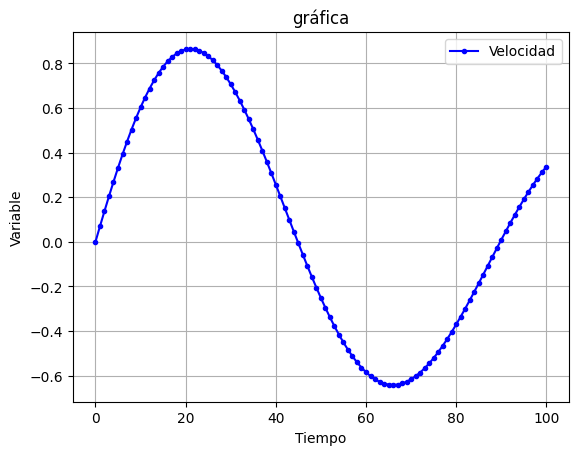

In [3]:
tiempo, velocidad = datos[0], datos[1]
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(tiempo, velocidad, label = "Velocidad", marker = ".", c = "blue")
plt.grid()
plt.legend(loc = "best")


## Distancia recorrida
Vamos a calcular la distancia recorrida en la dirección $x$, para ello notemos lo siguiente:

$$
\begin{aligned}
\text{Distancia total}
&= \frac{1}{2}\Big[
(t_1-t_0)(f(t_1)+f(t_0))\\
&\quad +(t_2-t_1)(f(t_2)+f(t_1))\\
&\quad +(t_3-t_2)(f(t_3)+f(t_2))\\
&\quad +\cdots
+(t_{101}-t_{100})(f(t_{101})+f(t_{100}))
\Big]\\[10pt]
&= \frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
\left[f(t_i)+f(t_{i+1})\right]
\right]
\end{aligned}
$$

Si definimos:

$$
f(t_i)=|V_i|
$$

Entonces:

$$
\boxed{
\text{Distancia total}
=
\frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
(|V_i|+|V_{i+1}|)
\right]
}
$$
Para sacar la base correcta debemos considerar que la función es positiva

In [4]:
Distancia = 0 #Definimos nuestras variables

for i in range(0,len(tiempo)-1):
    Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
    #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
distancia_total = Distancia/2
print(f"La distancia recorrida total es {distancia_total:.4} m")

La distancia recorrida total es 44.77 m


Para cada t, la distancia en el instante t se tiene lo siguiente

In [5]:
def distancia_recorrida(t):
    t = int(t)
    Distancia = 0 #Definimos nuestras variables
    if t>= 0 and t <= 100:
        for i in range(0,t):
            Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
            #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
        
        return Distancia/2
    if t>100 or t<0:
        print("Tu número debe de estar entre 0 y 100")
        return None
    

In [6]:
distancia= []
for i in range(0,101):
    print(f"la distancia recorrida en el instante t = {i} es {distancia_recorrida(i)}")
    distancia.append(distancia_recorrida(i))

la distancia recorrida en el instante t = 0 es 0.0
la distancia recorrida en el instante t = 1 es 0.034739
la distancia recorrida en el instante t = 2 es 0.138325
la distancia recorrida en el instante t = 3 es 0.309338
la distancia recorrida en el instante t = 4 es 0.5460455
la distancia recorrida en el instante t = 5 es 0.8464149999999999
la distancia recorrida en el instante t = 6 es 1.2081285
la distancia recorrida en el instante t = 7 es 1.6285975
la distancia recorrida en el instante t = 8 es 2.10498
la distancia recorrida en el instante t = 9 es 2.6341965
la distancia recorrida en el instante t = 10 es 3.212949
la distancia recorrida en el instante t = 11 es 3.83774
la distancia recorrida en el instante t = 12 es 4.504892
la distancia recorrida en el instante t = 13 es 5.2105685
la distancia recorrida en el instante t = 14 es 5.9507945
la distancia recorrida en el instante t = 15 es 6.721477999999999
la distancia recorrida en el instante t = 16 es 7.518431999999999
la distancia r

la cantidad de datos de tiempo es 101


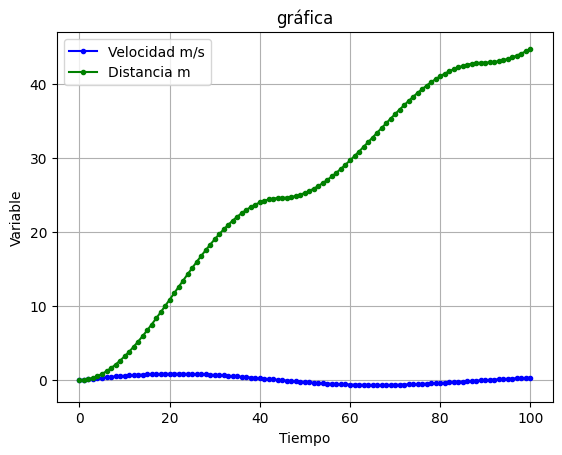

In [7]:
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(velocidad, label = "Velocidad m/s", marker = ".", c = "blue")
plt.plot( distancia, label = "Distancia m", marker = ".", c = "green")
plt.grid()
plt.legend(loc = "best")

# Ejercicio 2 

In [8]:
# Primero tenemos que la integral de Simpson está dada por: 
# Dada una función, tenemos un N = lo que quiera, y los límites de integración son a y b 

def IntegralSimpson(f, N, a,b):
    if N<= 0 or N % 2 != 0: 
        raise ValueError("N debe ser positivo y par")
    else:
        h = (b-a)/N
        suma_par = 0 
        suma_impar = 0 
        for i in range(1,int((N/2))):
            suma_par += f(a+(2*i*h))
        for i in range(1,int((N/2))+1):
            suma_impar += f(a+(2*i-1)*h)
        return (h/3)* ((f(a)+f(b))  + (4 * suma_impar) + (2 * suma_par))

## Inciso a) Escribir las funciones de Bessel

In [9]:
# Vamos a definir la función que va a dentro de la integral 
def cos_1(x,m, theta):
    return np.cos((m*theta)-(x*np.sin(theta)))

In [10]:
def J_Bessel(m, x):
    def f(theta):
        return cos_1(x, m, theta)

    return (1/np.pi)*IntegralSimpson(f, 1000, 0, np.pi)

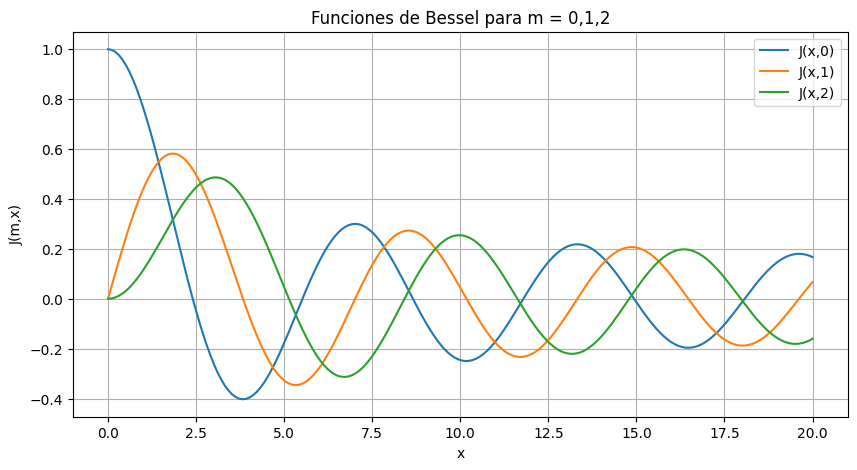

In [11]:
x_value = np.linspace(0,20, 200)
plt.figure(figsize=(10,5))
for i in range(3):
    plt.plot(x_value, J_Bessel(i, x_value), label = f"J(x,{i})")

plt.legend(loc = "best")
plt.title("Funciones de Bessel para m = 0,1,2")
plt.xlabel("x")
plt.ylabel("J(m,x)")
plt.grid()

## b) Comparación con scipy

In [12]:
from scipy.integrate import simpson

In [13]:
simpson?

Signature: simpson(y, x=None, *, dx=1.0, axis=-1)
Docstring:
Integrate y(x) using samples along the given axis and the composite
Simpson's rule. If x is None, spacing of dx is assumed.

Parameters
----------
y : array_like
    Array to be integrated.
x : array_like, optional
    If given, the points at which `y` is sampled.
dx : float, optional
    Spacing of integration points along axis of `x`. Only used when
    `x` is None. Default is 1.
axis : int, optional
    Axis along which to integrate. Default is the last axis.

Returns
-------
float
    The estimated integral computed with the composite Simpson's rule.

See Also
--------

:func:`quad`
    adaptive quadrature using QUADPACK
:func:`fixed_quad`
    fixed-order Gaussian quadrature
:func:`dblquad`
    double integrals
:func:`tplquad`
    triple integrals
:func:`romb`
    integrators for sampled data
:func:`cumulative_trapezoid`
    cumulative integration for sampled data
:func:`cumulative_simpson`
    cumulative integration usin

Tenemos que Scipy recibe valores de la función evaluada en los puntos de integración, Y = Puntos evaluados, x = puntos de evaluación 


In [14]:
# Función de Bessel calculada con SciPy
def J_Bessel_scipy(m, x):
    theta = np.linspace(0, np.pi)
    y_val = np.cos((m*theta)-(x*np.sin(theta)))
    return (1/np.pi) * simpson(y_val, theta)


In [15]:
x_value_sp = [[], [], []]
x_value = np.linspace(0,20, 200)
for i in x_value:
    for j in range(3):
        
        x_value_sp[j].append(J_Bessel_scipy(j,i))

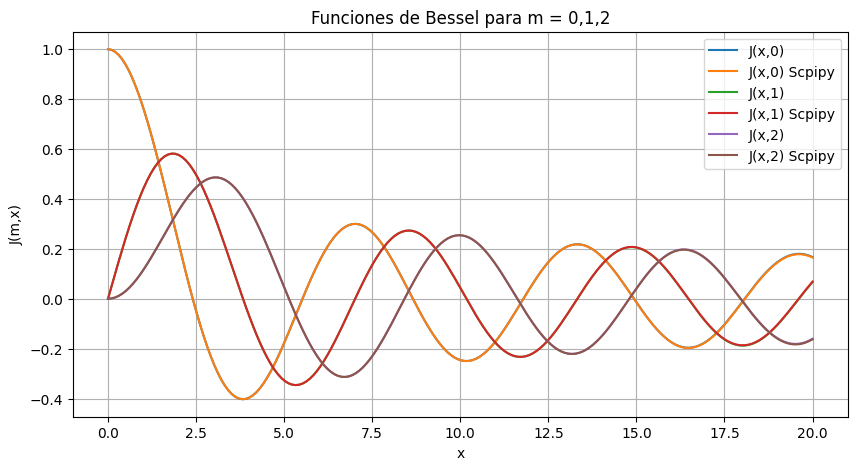

In [16]:

plt.figure(figsize=(10,5))
for i in range(3):
    plt.plot(x_value, J_Bessel(i, x_value), label = f"J(x,{i})")
    plt.plot(x_value, x_value_sp[i], label = f"J(x,{i}) Scpipy")
plt.legend(loc = "best")
plt.title("Funciones de Bessel para m = 0,1,2")
plt.xlabel("x")
plt.ylabel("J(m,x)")
plt.grid()

## c) Gráfica de densidad

In [17]:
# Primero creamos la fórmula de la Intensidad
def Intensidad(r,lamda):
    if r == 0:
        return 1/2
    if r>0 or r<0:
        k = (2*np.pi) / lamda
        return (J_Bessel(1, (k * r))/(k * r))**2

In [18]:
Intensidad(0, 0.550)

0.5

In [19]:
plt.imshow?

Signature:
plt.imshow(
    X: 'ArrayLike | PIL.Image.Image',
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    *,
    aspect: "Literal['equal', 'auto'] | float | None" = None,
    interpolation: 'str | None' = None,
    alpha: 'float | ArrayLike | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    colorizer: 'Colorizer | None' = None,
    origin: "Literal['upper', 'lower'] | None" = None,
    extent: 'tuple[float, float, float, float] | None' = None,
    interpolation_stage: "Literal['data', 'rgba', 'auto'] | None" = None,
    filternorm: 'bool' = True,
    filterrad: 'float' = 4.0,
    resample: 'bool | None' = None,
    url: 'str | None' = None,
    data=None,
    **kwargs,
) -> 'AxesImage'
Docstring:
Display data as an image, i.e., on a 2D regular raster.

The input may either be actual RGB(A) data, or 2D scalar data, which
will be rendered as a pseudocolor image. For displaying a grayscale
image, set up the col

In [20]:
np.meshgrid?

Signature:       np.meshgrid(*xi, copy=True, sparse=False, indexing='xy')
Call signature:  np.meshgrid(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function meshgrid at 0x000001FD77193740>
File:            c:\users\piloto 01\anaconda3\envs\cursodemachinglearning\lib\site-packages\numpy\lib\_function_base_impl.py
Docstring:      
Return a tuple of coordinate matrices from coordinate vectors.

Make N-D coordinate arrays for vectorized evaluations of
N-D scalar/vector fields over N-D grids, given
one-dimensional coordinate arrays x1, x2,..., xn.

Parameters
----------
x1, x2,..., xn : array_like
    1-D arrays representing the coordinates of a grid.
indexing : {'xy', 'ij'}, optional
    Cartesian ('xy', default) or matrix ('ij') indexing of output.
    See Notes for more details.
sparse : bool, optional
    If True the shape of the returned coordinate array for dimension *i*
    is reduced from ``(N1, ..., Ni, ... Nn)`` to
    ``(1, ..., 1, Ni, 1, ..., 1)``

In [21]:
x = np.linspace(-1, 1, 100)
y = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x, y)
R = (X**2  + Y ** 2)**(1/2)
R.shape

(100, 100)

In [22]:
#Creamos la matriz de ceros 
Z = np.zeros(R.shape)

In [23]:
for i in range(100):
    for j in range(100):
        Z[i,j] = Intensidad(R[i,j], 0.550)

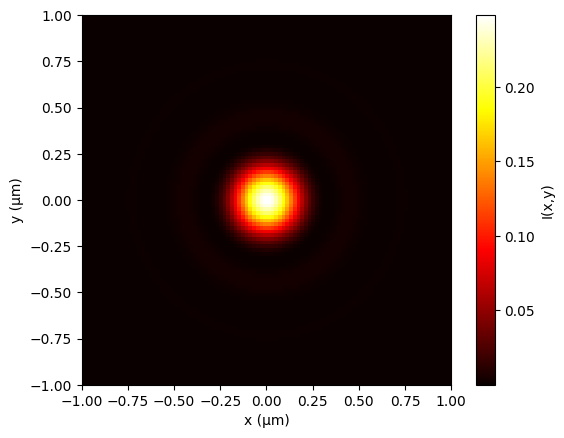

In [24]:
plt.imshow(Z, extent=[-1, 1, -1, 1], origin="lower", cmap="hot")
plt.colorbar(label="I(x,y)")
plt.xlabel("x (μm)")
plt.ylabel("y (μm)")
plt.show()

# 3. Capacidad calorífica de un sólido

## a) Función de capacidad calorífica de un sólido

In [25]:
def C_v(T):
    K_B = 1.380649* 10 *(-23) # J *K 
    densidad = 6.022* 10 *(-28) # metros ** -3
    V = 0.001  # metros cúbicos
    tetha_d = 428 # K 
    constante = 9 * V *densidad * K_B * (T / tetha_d) ** 3
    def dentro(x):
        if 
        return ((x**4) * (np.exp(x)))/((np.exp(x)-1)**2)
    integral = IntegralSimpson(dentro, 50, 0, (tetha_d/T))
    return constante * integral

SyntaxError: invalid syntax (1109201708.py, line 8)

# 4. Incertidumbre cuántica en el oscilador armónico

## a ) Función H_n(x)

In [ ]:
# Creamos la función de hermite de manera recursiva
def hermite(n,x):
    n = int(n)
    if n<0:
        raise ValueError("N debe ser positivo")
    if n == 0:
        return 1
    if n == 1:
        return 2*x
    if n>= 0: 
        return 2* x* hermite((n-1), x) - 2* (n-1) * hermite((n-2), x)


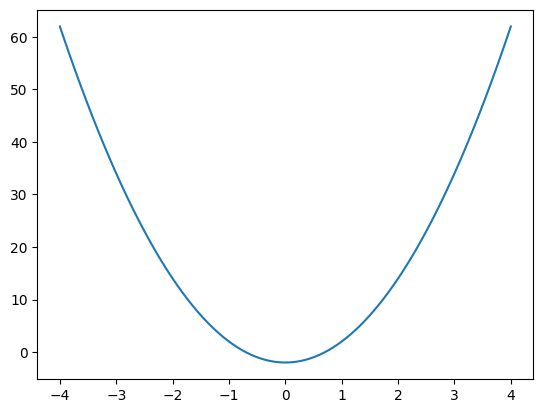

In [51]:
x_1 = np.linspace(-4,4, 100)
hermite(1,x_1).shape
plt.plot(x_1, hermite(2, x_1))

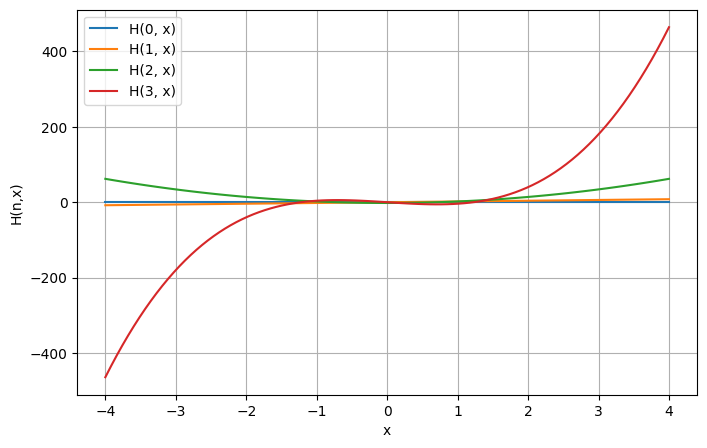

In [61]:
plt.figure(figsize=(8,5))
for i in range(0,4):
    if i == 0:
        plt.plot(x_1, np.ones(len(x_1)), label = f"H({i}, x)")
    if i != 0:
        plt.plot(x_1, hermite(i, x_1), label = f"H({i}, x)" )
plt.legend(loc = "best")
plt.xlabel("x")
plt.ylabel("H(n,x)")
plt.grid()

## Función de onda 

In [63]:
import math as mt

In [65]:
def funcion_de_onda(n,x):
    return (1/(np.sqrt((2**n)*(mt.factorial(n))*np.sqrt(np.pi)))) * np.exp(-(x**2)/2)*hermite(n,x)

In [68]:
x_2 = np.linspace(-10,10, 250)
y_2 = funcion_de_onda(30, x_2)


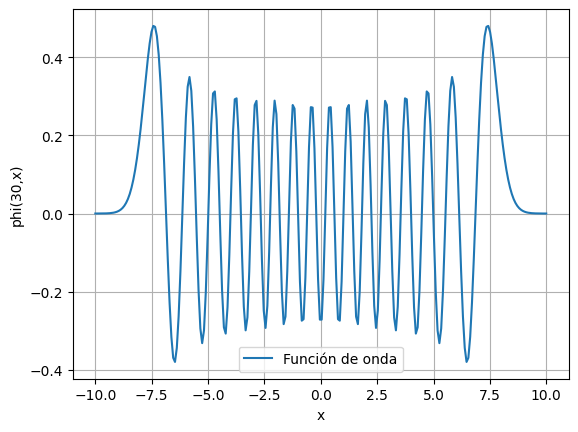

In [71]:
plt.plot(x_2, y_2, label = "Función de onda")
plt.legend(loc = "best")
plt.xlabel("x")
plt.ylabel("phi(30,x)")
plt.grid()